# Notebook n°2 : Analyse exploratoire

Problématique : Dans quelle mesure la structure du réseau TGV est-elle associée à la régularité des liaisons, et peut-on exploiter cette structure pour améliorer la prédiction des retards ?

Ce notebook fait suite au notebook n°1 (qualité des données, Marius).

## 1. Cadrage de l'étude

### 1.1 Type de question

Notre problematique repose principalement sur deux approches:

L'existence d'une relation entre la structure du reseau TGV et la regularite des liaisons et cette approche est exploratoire.

Essayer de determiner si les caracteristiques du reseau peuvent ameliorer la prediction des retards et cette approche est predictive. Notre etude n'est pas causal, on regarde des relations entre les caracteristiques du reseau et les retards mais on cherche pas a savoir si l'un provoque l'autre.

### 1.2 D'où viennent les données ?

Nos données publiées par la SNCF ne couvrent pas la totalité du réseau TGV du territoire français, mais uniquement les liaisons suivies par l'AQST. Certains services sont exclus. De plus, on a des liaisons saisonnières qui ne sont pas présentes toute l'année.

Les retards sont mesurés et communiqués par la SNCF elle-même. Les données sont regroupées par mois et non par jour, elles sont donc déjà agrégées et ne donnent pas de détails sur chaque circulation.


In [1]:
"""Chargement des données SNCF depuis le parquet nettoyé par l'ETL."""

from pathlib import Path

import pandas as pd

SEED = 42

# On remonte à la racine du projet si on est lancé depuis notebooks/
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# On charge le parquet produit par l'ETL de l'equipe
# les colonnes sont deja en snake_case, pas besoin de renommer
DATA_PATH = project_root / "data" / "processed" / "sncf.parquet"

data = pd.read_parquet(DATA_PATH)

print("Dimensions brutes :", data.shape)

# On ecarte les lignes marquees par les flags qualite
# (incoherences entre compteurs detectees par l'ETL)
colonnes_flags = [c for c in data.columns if c.startswith("flag_")]
a_un_flag = data[colonnes_flags].any(axis=1)

data = data.loc[~a_un_flag].drop(columns=colonnes_flags).copy()

print("Dimensions apres filtre qualite :", data.shape)
data.head()

Dimensions brutes : (12907, 30)
Dimensions apres filtre qualite : (12487, 26)


,date,service,gare_depart,gare_arrivee,duree_moyenne,nb_train_prevu,nb_annulation,commentaire_annulation,nb_train_depart_retard,retard_moyen_depart,...,nb_train_retard_sup_15,retard_moyen_trains_retard_sup15,nb_train_retard_sup_30,nb_train_retard_sup_60,prct_cause_externe,prct_cause_infra,prct_cause_gestion_trafic,prct_cause_materiel_roulant,prct_cause_gestion_gare,prct_cause_prise_en_charge_voyageurs
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.247809,...,110,6.511118,44,8,36.134454,31.092437,10.924370,15.966387,5.042017,0.840336
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.479969,...,32,5.363539,9,4,20.000000,35.000000,16.666667,16.666667,8.333333,3.333333
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.239683,...,11,2.938053,6,1,22.222222,27.777778,16.666667,16.666667,5.555556,11.111111
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.235211,...,39,5.292211,18,8,33.333333,22.222222,16.666667,20.370370,5.555556,1.851852
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.784673,...,42,4.882372,10,0,15.789474,45.614035,19.298246,15.789474,1.754386,1.754386


In [2]:
# Le notebook n°1 a vérifié que la clé (date, service, gare_depart,
# gare_arrivee) est unique : 0 doublon. On vérifie ici pourquoi
# le service doit faire partie de la clé.
doublons_sans_service = data.duplicated(
    subset=["date", "gare_depart", "gare_arrivee"], keep=False
)
print("Lignes en double si on ignore le service :", doublons_sans_service.sum())
print(data.loc[doublons_sans_service, "service"].value_counts())

data["liaison"] = data["gare_depart"] + " → " + data["gare_arrivee"]
gares = pd.concat([data["gare_depart"], data["gare_arrivee"]])

print("\nPériode            :", data["date"].min(), "→", data["date"].max())
print("Nombre de mois     :", data["date"].nunique())
print("Nombre de liaisons :", data["liaison"].nunique())
print("Nombre de gares    :", gares.nunique())

print("\nNombre de lignes par mois :")
data.groupby("date").size().describe()

Lignes en double si on ignore le service : 84
service
International    42
National         42
Name: count, dtype: int64

Période            : 2018-01 → 2026-09
Nombre de mois     : 105
Nombre de liaisons : 130
Nombre de gares    : 59

Nombre de lignes par mois :


count    105.000000
mean     118.923810
std       20.951269
min        1.000000
25%      121.000000
50%      121.000000
75%      123.000000
max      135.000000
dtype: float64

In [3]:
# Quand apparaissent les liaisons publiées en double (National + International) ?
paires = data.loc[doublons_sans_service, ["date", "liaison"]].drop_duplicates()
print("Première date :", paires["date"].min(), "| dernière :", paires["date"].max())
print(paires["liaison"].value_counts())

Première date : 2025-07 | dernière : 2025-09
liaison
PARIS LYON → MACON LOCHE                  3
BELLEGARDE (AIN) → PARIS LYON             3
MACON LOCHE → PARIS LYON                  3
MARSEILLE ST CHARLES → LYON PART DIEU     3
MULHOUSE VILLE → PARIS LYON               3
PARIS EST → STRASBOURG                    3
PARIS LYON → BELLEGARDE (AIN)             3
PARIS LYON → CHAMBERY CHALLES LES EAUX    3
STRASBOURG → PARIS EST                    3
CHAMBERY CHALLES LES EAUX → PARIS LYON    3
DIJON VILLE → PARIS LYON                  3
PARIS LYON → DIJON VILLE                  3
PARIS LYON → MULHOUSE VILLE               3
LYON PART DIEU → MARSEILLE ST CHARLES     3
Name: count, dtype: int64


In [4]:
# Quels mois ont le plus et le moins de lignes ?
lignes_par_mois = data.groupby("date").size()
print(lignes_par_mois.sort_values().head(5))
print(lignes_par_mois.sort_values().tail(5))

date
2025-03      1
2025-01      3
2025-02      4
2020-04     73
2020-05    112
dtype: int64
date
2018-09    130
2018-10    130
2025-07    135
2025-08    135
2025-09    135
dtype: int64



### Premiers observations

Notre jeu de données couvre 105 mois, de janvier 2018 à septembre 2026. Au total, nous avons 130 liaisons et 59 gares.

Le nombre de lignes varie selon les mois. En 2018, on avait 130 observations par mois, contre 121 sur une grande partie des periodes suivantes. Elle a baisse  118 en avril 2021 et a 119 certains mois de 2023 et 2024. Ces variations pourraient etre liees a des evenements comme le Covid. Ceci n'est pas confirme avec nos donnees.

Entre juillet et septembre 2025, 14 liaisons apparaissent à la fois en National et en International, ce qui explique en partie les 135 lignes par mois. Ces observations ne sont pas de vrais doublons puisque le service est différent. Il faut donc prendre en compte le mois, la liaison et le service pour identifier chaque observation.

Comme le nombre d'observations change au cours du temps, nous allons privilégier les taux de retard plutôt que les nombres bruts, afin de faire des comparaisons plus pertinentes.


## Le taux de retard

On cible  pour la suite une seule métrique: la part des trains en retard par liaison et par mois. 
on definit: $$ taux = \frac{\text{nombre de trains en retard}}{\text{nombre de trains ayant circulé}} $$
Au dénominateur, on prend les trains ayant circulé, pas les trains prévus : un train annulé n’a pas roulé, il n’est donc ni à l’heure, ni en retard.

Chaque ligne correspond à une liaison pendant un mois, mais le nombre de trains peut être différent d'une liaison à une autre. Si on fait simplement la moyenne des taux de retard, on donne la même importance à toutes les liaisons, même si certaines ont beaucoup plus de trains que d'autres.

Pour éviter cela, on utilisera un taux pondéré, calculé en divisant le nombre total de trains en retard par le nombre total de trains ayant circulé.

In [5]:

# On calcule le nombre de trains qui ont réellement circulé
data["circules"] = data["nb_train_prevu"] - data["nb_annulation"]

# On garde uniquement les lignes où au moins un train a circulé
data_propre = data[data["circules"] > 0].copy()
print(f"Lignes retirées : {len(data) - len(data_propre)}")


# Fonction pour calculer le taux de retard pondéré
def taux(df, colonne_retards="nb_train_retard_sup_15"):
    return df[colonne_retards].sum() / df["circules"].sum() * 100


# On compare la moyenne simple des taux avec le taux pondéré
taux_naif = (data_propre["nb_train_retard_sup_15"] / data_propre["circules"] * 100).mean()

taux_pondere = taux(data_propre)

print(f"Moyenne simple des taux : {taux_naif:.2f} %")
print(f"Taux pondéré            : {taux_pondere:.2f} %")


Lignes retirées : 10
Moyenne simple des taux : 11.50 %
Taux pondéré            : 10.63 %


## Deux mesures du retard dans le même fichier

jusqu'à présent, nous avons utilisé nb_train_retard_sup_15: le nombre de trains arrivés avec plus de 15 min de retard.

Mais on a la colonne nb_train_retard_arrivee, qui compte elle aussi les trains en retard, mais avec un seuil qui dépend de la durée du trajet. Par exemple pour les trajets de moins de 1h30, un train est en retard a partir de 5 minutes, contre 10 minutes pour les trajets entre 1h30 et 3h, et 15 minutes pour les trajets de plus de 3h. Cela signifie que pour les longs trajets les deux colonnes utilisent le même seuil. 

Les trajets plus courts ont un seuil plus faible avec nb_train_retard_arrivee.

Le choix de la colonne peut donc influencer nos résultats. Nous allons comparer les deux mesures pour voir les différences.

In [6]:
# On découpe les liaisons en 4 classes de durée du trajet.
data_propre["classe_duree"] = pd.cut(
    data_propre["duree_moyenne"],
    bins=[0, 90, 180, 300, 1000],
    labels=["< 1h30", "1h30 - 3h", "3h - 5h", "> 5h"],
)

# Pour chaque classe, on compare les deux mesures de retard.
comparaison = data_propre.groupby("classe_duree", observed=True).apply(lambda g: pd.Series({
    "trains (millions)":     g["circules"].sum() / 1e6,
    "taux officiel (%)":     taux(g, "nb_train_retard_arrivee"),
    "taux > 15 min (%)":     taux(g, "nb_train_retard_sup_15"),
    "rapport > 15 / officiel": g["nb_train_retard_sup_15"].sum() / g["nb_train_retard_arrivee"].sum(),
}))

comparaison.round(2)

,trains (millions),taux officiel (%),taux > 15 min (%),rapport > 15 / officiel
classe_duree,,,,
< 1h30,0.63,15.54,6.45,0.41
1h30 - 3h,1.77,14.23,10.04,0.71
3h - 5h,0.79,14.70,14.19,0.97
> 5h,0.12,17.51,17.52,1.00


### Ce qu'on observe avec les deux mesures

Pour les trajets de plus de 5h on remarque que les deux colonnes donnent les mêmes résultats. C'est cohérent avec la règle SNCF (source : la documentation du dataset sur ressources.data.sncf.com), car pour les longs trajets, le seuil officiel est de 15 minutes.

Tandis que pour les trajets plus courts, le rapport peut descendre à 0,42. Cela s'explique par le fait que le seuil officiel est plus faible pour ces trajets (5 ou 10 minutes).

On remarque aussi que les taux de retard officiels sont assez proches pour toutes les durées, entre 14 et 17 %. Par contre, avec un seuil fixe de 15 minutes, le taux passe d'environ 6 % pour les trajets courts à 17 % pour les trajets très longs.

Ensuite, nous allons utiliser le taux de retard supérieur à 15 minutes comme indicateur principal, afin de comparer les liaisons avec le même seuil. Le taux officiel sera conservé pour vérifier nos résultats.

Il faudra aussi faire attention à la durée des trajets, notamment pour les liaisons internationales ou transversales, afin de ne pas confondre l'effet de la durée avec celui de la structure du réseau.

Il faut aussi noter qu'un même TGV peut apparaître dans plusieurs liaisons. Ainsi, lorsque nous regroupons plusieurs liaisons pour calculer un taux global, certains trains peuvent être comptés plusieurs fois, ce qui peut influencer nos résultats.

## 3. Évolution du taux de retard dans le temps

Jusqu'à présent, nous avons étudié les données dans leur ensemble. Nous allons regarder comment le taux de retard évolue chaque mois entre 2018 et 2026.

Notre but c'est de chercher à voir s'il existe des différences selon les saisons, si les retards augmentent ou diminuent au fil des années et si certains événements comme les grèves, le Covid ou les canicules ont marqué certaines périodes.

On va utiliser le taux pondéré défini dans la partie précédente, car le nombre de trains varie selon les mois.

Nous ferons attention à la période du confinement (2020) qui a été détectée par Marius dans le notebook 1, pour eviter de la comparer a une période normale.

In [7]:

# On regroupe les données par mois et on additionne les retards, les trains et les annulations
par_mois = data_propre.groupby("date").agg(
    retards_15=("nb_train_retard_sup_15", "sum"),
    retards_arrivee=("nb_train_retard_arrivee", "sum"),
    trains=("circules", "sum"),
    annulations=("nb_annulation", "sum"),
)

# On calcule les deux taux de retard et le taux d'annulation pour chaque mois
par_mois["taux_15"] = par_mois["retards_15"] / par_mois["trains"] * 100
par_mois["taux_officiel"] = par_mois["retards_arrivee"] / par_mois["trains"] * 100
par_mois["taux_annulation"] = par_mois["annulations"] / (par_mois["trains"] + par_mois["annulations"]) * 100

# On transforme les mois en dates pour les utiliser dans les graphiques
par_mois.index = pd.to_datetime(par_mois.index + "-01")

# On affiche les taux avec deux chiffres après la virgule
par_mois[["taux_15", "taux_officiel", "taux_annulation"]].round(2)


,taux_15,taux_officiel,taux_annulation
date,,,
2018-01-01,9.99,15.08,0.75
2018-02-01,15.65,21.91,2.26
2018-03-01,9.89,15.16,2.62
2018-04-01,10.85,16.66,32.67
2018-05-01,11.72,17.35,24.54
...,...,...,...
2026-05-01,14.26,18.33,0.42
2026-06-01,19.37,23.88,3.85
2026-07-01,19.07,24.29,2.18


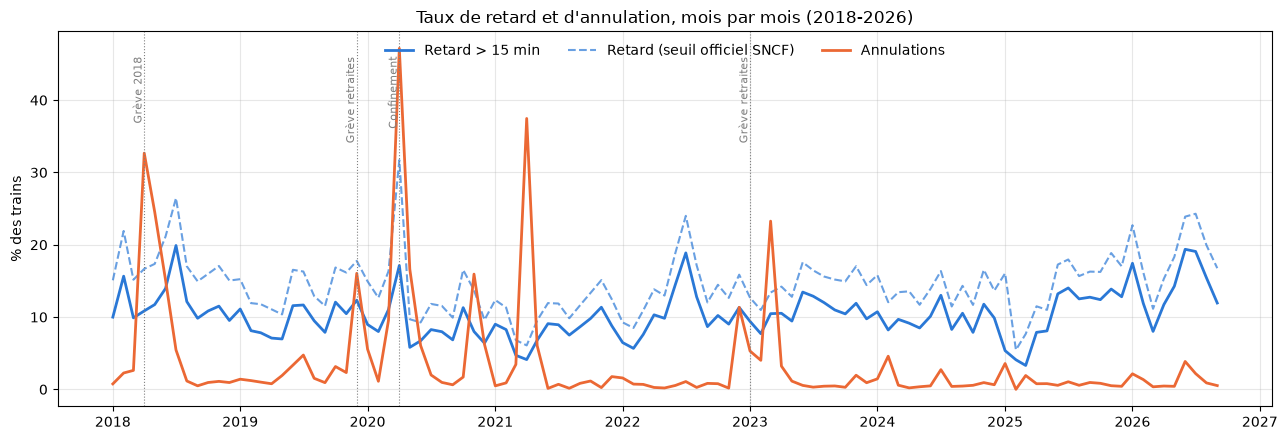

In [8]:

import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(13, 4.5))

# On affiche les deux taux de retard et le taux d'annulation
ax.plot(par_mois.index, par_mois["taux_15"], color="#2a78d6", lw=2,
        label="Retard > 15 min")
ax.plot(par_mois.index, par_mois["taux_officiel"], color="#2a78d6", lw=1.5,
        ls="--", alpha=0.7, label="Retard (seuil officiel SNCF)")
ax.plot(par_mois.index, par_mois["taux_annulation"], color="#eb6834", lw=2,
        label="Annulations")

# On ajoute des lignes verticales pour repérer certains événements
evenements = {
    "2018-04-01": "Grève 2018",
    "2019-12-01": "Grève retraites",
    "2020-04-01": "Confinement",
    "2023-01-01": "Grève retraites",
}
for date, nom in evenements.items():
    ax.axvline(pd.Timestamp(date), color="gray", lw=0.8, ls=":")
    ax.text(pd.Timestamp(date), 46, nom, rotation=90,
            va="top", ha="right", fontsize=8, color="gray")

# On ajoute le titre, la légende et la grille
ax.set_ylabel("% des trains")
ax.set_title("Taux de retard et d'annulation, mois par mois (2018-2026)")
ax.legend(frameon=False, loc="upper center", ncol=3)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


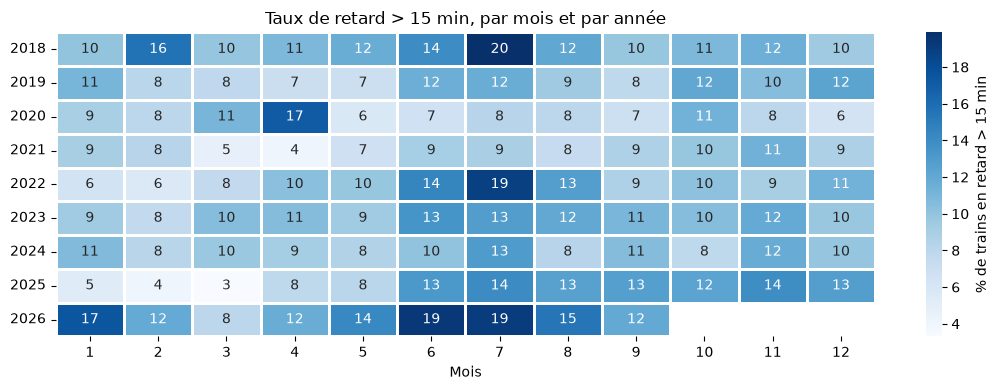

In [9]:

import seaborn as sns

# On récupère l'année et le mois de chaque date
par_mois["annee"] = par_mois.index.year
par_mois["mois"] = par_mois.index.month

# On organise les taux de retard par année et par mois
grille = par_mois.pivot(index="annee", columns="mois", values="taux_15")

# On crée une carte de chaleur pour visualiser les différences
fig, ax = plt.subplots(figsize=(11, 4))
sns.heatmap(
    grille,
    cmap="Blues",
    annot=True,
    fmt=".0f",
    linewidths=2,
    linecolor="white",
    cbar_kws={"label": "% de trains en retard > 15 min"},
    ax=ax,
)

ax.set_xlabel("Mois")
ax.set_ylabel("")
ax.set_title("Taux de retard > 15 min, par mois et par année")
plt.tight_layout()
plt.show()


In [10]:

# On garde janvier à septembre pour toutes les années, car 2026 s'arrête en septembre
par_annee = data_propre[data_propre["date"].str[5:7].astype(int) <= 9].groupby(
    data_propre[data_propre["date"].str[5:7].astype(int) <= 9]["date"].str[:4]
).agg(
    retards_15=("nb_train_retard_sup_15", "sum"),
    retards_officiel=("nb_train_retard_arrivee", "sum"),
    trains=("circules", "sum"),
    annulations=("nb_annulation", "sum"),
)

# On calcule les taux de retard et d'annulation pour chaque année
par_annee["taux_15 (%)"] = par_annee["retards_15"] / par_annee["trains"] * 100
par_annee["taux_officiel (%)"] = par_annee["retards_officiel"] / par_annee["trains"] * 100
par_annee["taux_annulation (%)"] = par_annee["annulations"] / (
    par_annee["trains"] + par_annee["annulations"]
) * 100

# On affiche les trois taux avec deux chiffres après la virgule
par_annee[["taux_15 (%)", "taux_officiel (%)", "taux_annulation (%)"]].round(2)


,taux_15 (%),taux_officiel (%),taux_annulation (%)
date,,,
2018,12.69,18.42,9.73
2019,9.10,13.09,1.90
2020,8.10,12.24,4.71
2021,7.66,10.39,5.50
2022,10.67,14.34,0.68
2023,10.83,14.41,4.30
2024,9.81,13.63,1.23
2025,11.38,14.92,0.79
2026,14.35,18.73,1.36


### Ce qu'on observe sur l'évolution des retards

Nous remarquons d'abord que les retards varient selon les saisons. Les mois de juin et juillet semblent souvent plus touchés, ce qui pourrait être lié à une plus forte affluence, aux travaux ou aux conditions météorologiques comme les canicules.

On observe également des périodes particulières avec des pics d'annulations, notamment pendant les grèves de 2018, 2019 et 2023, ainsi que les confinements liés au Covid en 2020 et 2021. Nous allons donc faire attention à ces périodes dans la suite de notre analyse.

En comparant uniquement les mois de janvier à septembre, 2026 présente le taux de retard supérieur à 15 minutes le plus élevé**, avec 14,35 %, contre 12,69 % en 2018 et environ 10 % entre 2022 et 2025.

On remarque aussi que les taux officiels de retard sont proches entre 2018 et 2026 (18,4 % et 18,7 %). Par contre, le taux d'annulation est beaucoup plus élevé en 2018 (9,7 %) qu'en 2026 (1,4 %).

Ces résultats montrent une différence entre les deux années, mais ne permettent pas encore d'affirmer que le réseau s'est dégradé structurellement. Il faudra étudier les liaisons et les caractéristiques du réseau pour mieux comprendre cette évolution.

## 4. Localiser les liaisons et étudier leur fiabilité

Avec la section n°3, on a pu observer les variations des retards au fil du temps (variations saisonnières, grèves, etc.). Mais nous avons regardé le réseau dans son ensemble. On ne sait donc pas encore si les retards touchent toutes les liaisons de la même manière ou si certaines sont beaucoup plus touchées que d'autres.

Dans cette partie du notebook, nous allons analyser les liaisons une par une. On veut identifier les liaisons les plus problématiques, puis voir si ces écarts restent présents au fil du temps.

Nous allons également regarder si les résultats changent selon le nombre de trains qui circulent sur chaque liaison et si les retards sont différents selon le sens du trajet.


In [11]:

# On regroupe les données par liaison pour calculer les totaux sur toute la période
par_liaison = data_propre.groupby("liaison").agg(
    trains=("circules", "sum"),
    retards_15=("nb_train_retard_sup_15", "sum"),
    retards_arrivee=("nb_train_retard_arrivee", "sum"),
    duree=("duree_moyenne", "mean"),
    nb_mois=("date", "nunique"),
)

# On calcule les deux taux de retard pour chaque liaison
par_liaison["taux_15"] = par_liaison["retards_15"] / par_liaison["trains"] * 100
par_liaison["taux_officiel"] = par_liaison["retards_arrivee"] / par_liaison["trains"] * 100

# On affiche le nombre total de liaisons et les 5 premières lignes
print("Nombre de liaisons :", len(par_liaison))
par_liaison.head()


Nombre de liaisons : 130


,trains,retards_15,retards_arrivee,duree,nb_mois,taux_15,taux_officiel
liaison,,,,,,,
AIX EN PROVENCE TGV → PARIS LYON,40959,4816,4954,186.333333,102,11.758100,12.095022
ANGERS SAINT LAUD → PARIS MONTPARNASSE,47221,4404,7261,94.627451,102,9.326359,15.376633
ANGOULEME → PARIS MONTPARNASSE,27311,3077,4571,128.098039,102,11.266523,16.736846
ANNECY → PARIS LYON,13747,2779,2779,227.564356,101,20.215320,20.215320
ARRAS → PARIS NORD,40088,3043,8812,51.000000,102,7.590800,21.981640


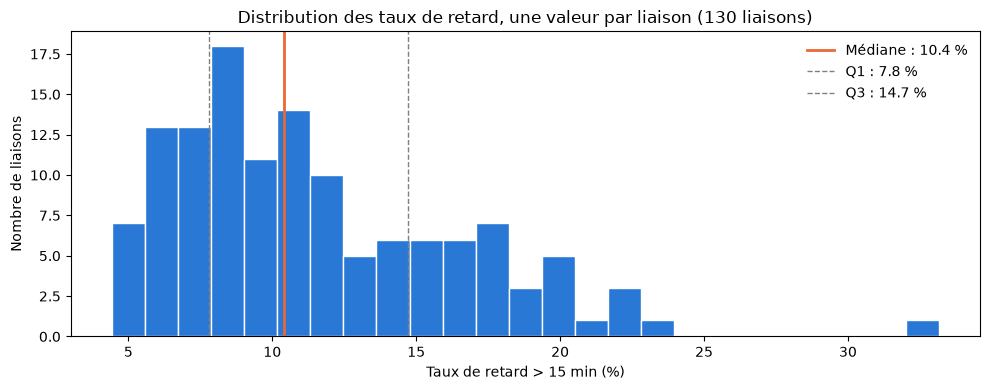

count    130.00
mean      11.56
std        5.00
min        4.43
25%        7.79
50%       10.39
75%       14.73
max       33.15
Name: taux_15, dtype: float64

In [12]:

# On regarde comment les taux de retard sont répartis entre les 130 liaisons
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(par_liaison["taux_15"], bins=25, color="#2a78d6", edgecolor="white")

# On calcule la médiane et les deux quartiles pour les afficher sur le graphique
mediane = par_liaison["taux_15"].median()
q1 = par_liaison["taux_15"].quantile(0.25)
q3 = par_liaison["taux_15"].quantile(0.75)

ax.axvline(mediane, color="#eb6834", lw=2, label=f"Médiane : {mediane:.1f} %")
ax.axvline(q1, color="gray", lw=1, ls="--", label=f"Q1 : {q1:.1f} %")
ax.axvline(q3, color="gray", lw=1, ls="--", label=f"Q3 : {q3:.1f} %")

# On ajoute les titres des axes et la légende
ax.set_xlabel("Taux de retard > 15 min (%)")
ax.set_ylabel("Nombre de liaisons")
ax.set_title("Distribution des taux de retard, une valeur par liaison (130 liaisons)")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

# On affiche les statistiques générales des taux de retard
par_liaison["taux_15"].describe().round(2)


L'histogramme nous montre que la plupart des liaisons ont un taux de retard compris entre 5 % et 15 %, avec une concentration autour de 8 à 10 %.

La médiane est de 10,4 %, ce qui signifie que la moitié des liaisons ont un taux inférieur à cette valeur et l'autre moitié un taux supérieur. On observe également que 50 % des liaisons ont un taux compris entre 7,8 % et 14,7 %.

On peut aussi voir qu’il existe certaines liaisons qui présentent des taux beaucoup plus élevés, notamment une qui dépasse les 30 %.

Ces différences peuvent être liées à des difficultés propres à certaines liaisons et au faible nombre de trains sur certaines d'entre elles, ce qui peut rendre les taux plus variables.

Nous allons donc utiliser le funnel plot pour examiner ces différences en tenant compte du nombre de trains.

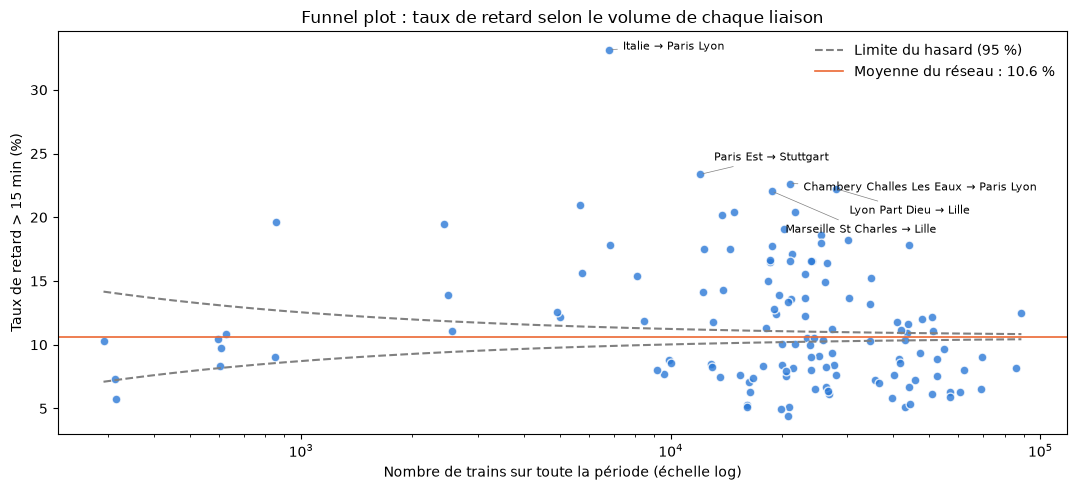

In [13]:

import numpy as np

# On calcule le taux de retard moyen pondéré de toutes les liaisons
p0 = par_liaison["retards_15"].sum() / par_liaison["trains"].sum()

# On calcule les limites à 95 % selon le nombre de trains
n_range = np.logspace(
    np.log10(par_liaison["trains"].min()),
    np.log10(par_liaison["trains"].max()),
    200,
)

ecart_type = np.sqrt(p0 * (1 - p0) / n_range)
limite_haute = (p0 + 1.96 * ecart_type) * 100
limite_basse = (p0 - 1.96 * ecart_type) * 100

# On crée le graphique avec un point pour chaque liaison
fig, ax = plt.subplots(figsize=(11, 5))

ax.scatter(par_liaison["trains"], par_liaison["taux_15"],
           s=40, color="#2a78d6", edgecolor="white", alpha=0.8)

# On ajoute les deux limites et la moyenne du réseau
ax.plot(n_range, limite_haute, color="gray", ls="--", label="Limite du hasard (95 %)")
ax.plot(n_range, limite_basse, color="gray", ls="--")
ax.axhline(p0 * 100, color="#eb6834", lw=1.2, label=f"Moyenne du réseau : {p0*100:.1f} %")

# On affiche le nom des 5 liaisons avec les taux de retard les plus élevés
decalages = {0: (10, 0), 1: (10, 10), 2: (10, -5), 3: (10, -18), 4: (10, -30)}
for rang, (nom, ligne) in enumerate(par_liaison.nlargest(5, "taux_15").iterrows()):
    ax.annotate(nom.title(),
                (ligne["trains"], ligne["taux_15"]),
                fontsize=8,
                xytext=decalages[rang],
                textcoords="offset points",
                arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# On ajoute les titres des axes et la légende
ax.set_xscale("log")
ax.set_xlabel("Nombre de trains sur toute la période (échelle log)")
ax.set_ylabel("Taux de retard > 15 min (%)")
ax.set_title("Funnel plot : taux de retard selon le volume de chaque liaison")
ax.legend(frameon=False, loc="upper right")

plt.tight_layout()
plt.show()


Presque toutes les liaisons se trouvent en dehors des limites de l'entonnoir (les pointillés). Ces limites représentent les variations qu'on pourrait observer simplement à cause du hasard, si toutes les liaisons avaient le même taux de retard.

Vu que beaucoup de points dépassent ces limites, cela suggère que les différences de retard entre les liaisons ne s'expliquent pas uniquement par le hasard.

On constate donc des différences importantes entre les taux de retard des liaisons. Dans la suite, nous allons chercher à voir si ces différences sont liées aux caractéristiques du réseau TGV.

In [14]:

# On calcule le taux de retard de chaque liaison pour chaque année
par_an = data_propre.groupby(["liaison", data_propre["date"].str[:4]]).agg(
    retards=("nb_train_retard_sup_15", "sum"),
    trains=("circules", "sum"),
)

par_an["taux"] = par_an["retards"] / par_an["trains"] * 100

# On organise les résultats avec les liaisons en lignes et les années en colonnes
annees = par_an["taux"].unstack()
annees.columns.name = "annee"

# On affiche les dimensions du tableau et les 5 premières lignes
print("Forme du tableau :", annees.shape)
annees.head()


Forme du tableau : (130, 9)


annee,2018,2019,2020,2021,2022,2023,2024,2025,2026
liaison,,,,,,,,,
AIX EN PROVENCE TGV → PARIS LYON,11.516484,11.535088,7.904231,8.793970,11.248654,11.513220,11.652237,14.678236,16.849817
ANGERS SAINT LAUD → PARIS MONTPARNASSE,10.307372,8.556701,8.452606,8.294011,9.109632,9.567705,7.540230,9.336914,13.412878
ANGOULEME → PARIS MONTPARNASSE,12.348754,9.918167,8.448118,7.329105,11.833069,12.630423,12.014329,11.240029,14.569790
ANNECY → PARIS LYON,27.020327,15.418502,13.948919,21.979522,22.789539,18.672930,14.356984,25.312500,20.395257
ARRAS → PARIS NORD,7.978573,6.842105,6.858890,5.030783,8.389381,7.506608,6.917581,9.389895,10.084898


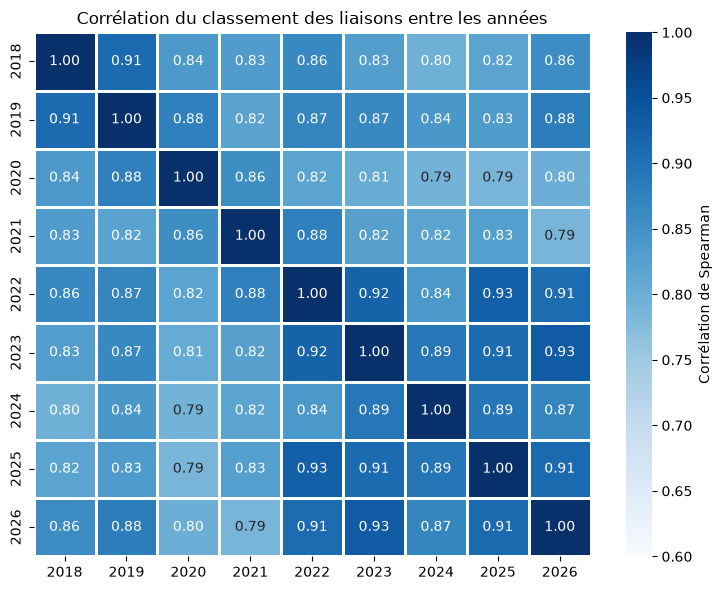

In [15]:
# Corrélation de Spearman entre toutes les paires d'années.
# Spearman regarde les rangs, pas les valeurs : si une liaison est 3e en 2018 et 3e en 2019, ça compte comme une concordance.
corr_annees = annees.corr(method="spearman")

# Affichage en heatmap.
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(
    corr_annees,
    cmap="Blues",
    vmin=0.6, vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Corrélation de Spearman"},
    ax=ax,
)
ax.set_title("Corrélation du classement des liaisons entre les années")
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

Cette matrice de corrélation de Spearman nous offre une vision claire sur la similarité du classement des liaisons entre les années.

Les corrélations sont élevées, entre 0,79 et 0,93, avec 0,86 entre 2018 et 2026. Elles sont un peu plus faibles en 2020, probablement à cause du Covid.

Cela montre que les liaisons les plus touchées par les retards ont tendance à le rester au fil des années, ce qui suggère des différences durables entre les liaisons.

In [16]:

# On regroupe les deux sens d'une même liaison sous un seul nom
par_liaison["paire"] = [" ↔ ".join(sorted(l.split(" → "))) for l in par_liaison.index]

# On garde uniquement les liaisons présentes dans les deux sens
paires_bi = par_liaison.groupby("paire").filter(lambda g: len(g) == 2)

# On compare les taux de retard des deux sens pour chaque paire
resume_sens = paires_bi.groupby("paire").apply(lambda g: pd.Series({
    "pire_sens": g["taux_15"].idxmax(),
    "taux_pire": g["taux_15"].max(),
    "taux_meilleur": g["taux_15"].min(),
    "ecart": g["taux_15"].max() - g["taux_15"].min(),
}))

# On affiche le nombre de paires et l'écart médian entre les deux sens
print("Nombre de paires avec les deux sens :", len(resume_sens))
print("Écart médian entre les deux sens :", resume_sens["ecart"].median().round(2), "points")

# On affiche les 10 paires avec les plus grandes différences de taux
print("\nLes 10 paires les plus asymétriques :")
resume_sens.sort_values("ecart", ascending=False).head(10).round(2)


Nombre de paires avec les deux sens : 65
Écart médian entre les deux sens : 1.76 points

Les 10 paires les plus asymétriques :


,pire_sens,taux_pire,taux_meilleur,ecart
paire,,,,
ITALIE ↔ PARIS LYON,ITALIE → PARIS LYON,33.15,17.82,15.33
MACON LOCHE ↔ PARIS LYON,MACON LOCHE → PARIS LYON,20.43,8.18,12.25
MADRID ↔ MARSEILLE ST CHARLES,MADRID → MARSEILLE ST CHARLES,19.65,9.05,10.60
CHAMBERY CHALLES LES EAUX ↔ PARIS LYON,CHAMBERY CHALLES LES EAUX → PARIS LYON,22.65,13.33,9.32
MARSEILLE ST CHARLES ↔ TOURCOING,MARSEILLE ST CHARLES → TOURCOING,19.46,10.27,9.18
LILLE ↔ LYON PART DIEU,LYON PART DIEU → LILLE,22.25,13.65,8.59
LYON PART DIEU ↔ MARSEILLE ST CHARLES,LYON PART DIEU → MARSEILLE ST CHARLES,17.84,10.91,6.93
ANNECY ↔ PARIS LYON,ANNECY → PARIS LYON,20.22,14.26,5.95
PARIS EST ↔ STUTTGART,PARIS EST → STUTTGART,23.37,17.50,5.86


In [17]:
# Classement global : les trajets vers Paris sont-ils en moyenne plus en retard ?
par_liaison["vers_paris"] = par_liaison.index.str.endswith("PARIS LYON") | \
                            par_liaison.index.str.endswith("PARIS MONTPARNASSE") | \
                            par_liaison.index.str.endswith("PARIS NORD") | \
                            par_liaison.index.str.endswith("PARIS EST") | \
                            par_liaison.index.str.endswith("PARIS VAUGIRARD")
par_liaison["depuis_paris"] = par_liaison.index.str.startswith("PARIS ")

# Taux pondéré selon le sens.
for sens, mask in [("Vers Paris", par_liaison["vers_paris"]),
                   ("Depuis Paris", par_liaison["depuis_paris"]),
                   ("Ni au départ ni à l'arrivée à Paris", ~par_liaison["vers_paris"] & ~par_liaison["depuis_paris"])]:
    sous = par_liaison[mask]
    taux_moyen = sous["retards_15"].sum() / sous["trains"].sum() * 100
    print(f"{sens:40s} : {len(sous):3d} liaisons, taux pondéré {taux_moyen:.2f} %")

Vers Paris                               :  54 liaisons, taux pondéré 10.74 %
Depuis Paris                             :  54 liaisons, taux pondéré 9.10 %
Ni au départ ni à l'arrivée à Paris      :  22 liaisons, taux pondéré 16.15 %


On remarque que pour la majorité des liaisons, les deux sens ont des taux de retard assez proches, avec un écart médian de 1,8 point. Cependant, certaines présentent des différences importantes, par example Italie vers Paris et Mâcon vers Paris.

Ceci peut etre explique par le fait que certains trains viennent de plus loin et accumulent des retards avant d'arriver sur la liaison étudiée.

De maniére generale les trajets depuis Paris ont un taux de retard de 9,10 %, contre 10,74 % vers Paris et 16,15 % pour les liaisons transversales.

Ces différences pourraient aussi être liées à la durée des trajets. Nous allons donc étudier ce point dans la section suivante.

Pour conclure cette partie, on peut dire que les différences importantes de taux de retard entre les liaisons ne semblent pas être dues uniquement au hasard, vu qu'elles restent assez stables au fil des années.

Les trajets depuis Paris présentent les taux de retard les plus faibles, tandis que les liaisons transversales et certains trajets vers Paris sont plus touchés.

Ces différences pourraient être liées à la durée des trajets, surtout pour les liaisons transversales et internationales, qui sont généralement plus longues.

Dans la prochaine section, on va essayer de comparer les taux de retard à durée similaire pour voir si les caractéristiques du réseau sont aussi associées aux retards.

## 5. L'effet de la durée

Après avoir remarqué que les liaisons transversales ont des taux de retard élevés, on va essayer de voir si ces taux sont liés à la position de ces liaisons dans le réseau ou à la durée du trajet.

Pour cela, on va s'intéresser au paradoxe de Simpson. C'est un phénomène statistique où une relation entre deux groupes peut changer lorsqu'on prend en compte une autre variable. Dans notre analyse, cette variable sera la durée du trajet.

Nous allons donc comparer les taux de retard à durée similaire, afin de voir si les différences restent présentes.

In [18]:

# On classe les liaisons selon leur type
paris_gares = ["PARIS LYON", "PARIS MONTPARNASSE", "PARIS NORD", "PARIS EST",
               "PARIS VAUGIRARD"]

def type_liaison(ligne):
    depart = ligne["gare_depart"]
    arrivee = ligne["gare_arrivee"]

    if ligne["service"] == "International":
        return "international"
    if depart in paris_gares:
        return "radiale depuis Paris"
    if arrivee in paris_gares:
        return "radiale vers Paris"
    return "transversale"

# On ajoute le type de chaque liaison dans une nouvelle colonne
data_propre["type_liaison"] = data_propre.apply(type_liaison, axis=1)

# On compte les observations pour chaque type de liaison
data_propre["type_liaison"].value_counts()


type_liaison
radiale vers Paris      4524
radiale depuis Paris    4523
transversale            1929
international           1501
Name: count, dtype: int64

In [19]:
# on decoupe les durees en 4 classes pour pouvoir comparer a duree equivalente

tranches = [0, 90, 180, 300, 10000]
etiquettes = ["< 1h30", "1h30 - 3h", "3h - 5h", "> 5h"]

data_propre["classe_duree"] = pd.cut(data_propre["duree_moyenne"],
                                     bins=tranches,
                                     labels=etiquettes)


data_propre["classe_duree"].value_counts().sort_index()

classe_duree
< 1h30       2068
1h30 - 3h    5381
3h - 5h      3826
> 5h         1202
Name: count, dtype: int64

In [20]:
# taux de retard pour chaque combinaison type x classe de duree

croisement = (data_propre
              .groupby(["type_liaison", "classe_duree"], observed=True)
              .apply(taux)
              .unstack())

croisement.round(2)

classe_duree,< 1h30,1h30 - 3h,3h - 5h,> 5h
type_liaison,,,,
international,16.67,14.91,14.44,21.43
radiale depuis Paris,5.81,8.30,12.08,16.61
radiale vers Paris,7.12,10.48,13.64,17.48
transversale,NaN,14.71,18.06,14.51


In [21]:
# nombre total de trains observes dans chaque combinaison, plus le volume est grand, plus le taux est fiable

volumes = (data_propre
           .groupby(["type_liaison", "classe_duree"], observed=True)["circules"]
           .sum()
           .unstack())

volumes.astype("Int64")

classe_duree,< 1h30,1h30 - 3h,3h - 5h,> 5h
type_liaison,,,,
international,18,17116,134429,23761
radiale depuis Paris,321962,768657,249757,40046
radiale vers Paris,306308,790371,245920,41287
transversale,<NA>,194318,164073,18396


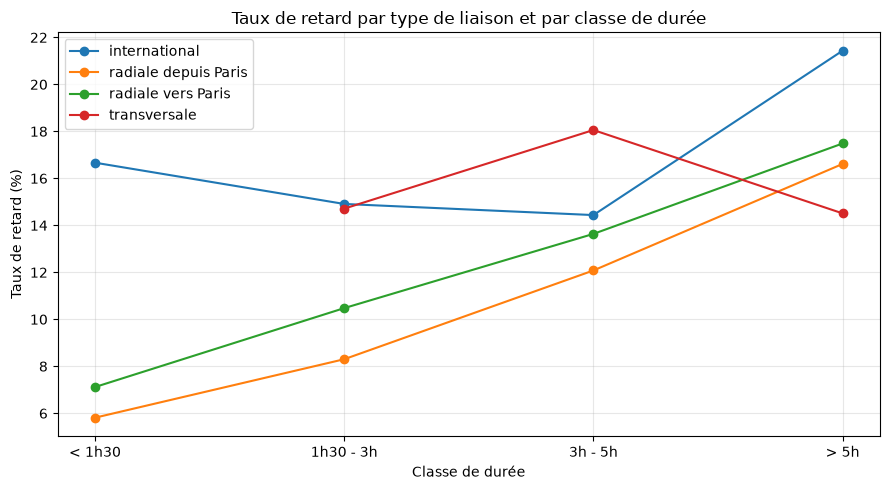

In [22]:

import matplotlib.pyplot as plt

# On compare les taux de retard selon la durée et le type de liaison
fig, ax = plt.subplots(figsize=(9, 5))

# On trace une courbe pour chaque type de liaison
for type_ in croisement.index:
    ax.plot(croisement.columns, croisement.loc[type_],
            marker="o", label=type_)

# On ajoute le titre, les axes et la légende
ax.set_xlabel("Classe de durée")
ax.set_ylabel("Taux de retard (%)")
ax.set_title("Taux de retard par type de liaison et par classe de durée")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


On remarque que les taux de retard des liaisons radiales augmentent avec la durée du trajet, de manière presque parallèle.

Entre 1h30 et 5h, les liaisons transversales présentent des taux de retard plus élevés que les radiales.

Cela suggère que la durée du trajet ne suffit pas à expliquer toutes les différences. Les caractéristiques du réseau pourraient aussi jouer un rôle.

Pour les trajets de plus de 5h, les résultats sont différents : les taux des transversales diminuent, tandis que ceux des internationales augmentent fortement. Nous allons donc nous concentrer sur les durées les plus représentées dans nos données pour la suite.

In [23]:

# On calcule un taux ajusté en donnant le même poids à chaque classe de durée
taux_ajuste = croisement.mean(axis=1, skipna=True).round(2)

# On calcule aussi le taux global de chaque type de liaison
taux_brut = (data_propre.groupby("type_liaison", observed=True)
             .apply(taux)
             .round(2))

# On rassemble les deux taux pour les comparer
comparaison = pd.DataFrame({
    "taux brut (%)": taux_brut,
    "taux ajuste par duree (%)": taux_ajuste
}).sort_values("taux ajuste par duree (%)")

comparaison


,taux brut (%),taux ajuste par duree (%)
type_liaison,,
radiale depuis Paris,8.64,10.70
radiale vers Paris,10.50,12.18
transversale,16.16,15.76
international,15.43,16.86


### Ce qu'on retient de la section 5

On remarque que l'écart entre les liaisons radiales depuis Paris et les transversales passe de **7,5 points à environ 5 points** après avoir pris en compte la durée des trajets.

Cela suggère que la durée explique une partie des différences, mais pas la totalité. Même après ajustement, les transversales présentent des taux de retard plus élevés que les radiales.

Les liaisons internationales ont également des taux élevés après ajustement, ce qui pourrait être lié à d'autres facteurs, comme leur dépendance aux réseaux étrangers.

Dans la prochaine section, nous allons étudier directement la structure du réseau TGV pour voir si certaines gares ou zones du réseau sont associées à davantage de retards.

## 6. Le réseau TGV sous forme de graphe

Jusqu'à présent, nous avons étudié les liaisons séparément. Dans cette section, nous allons représenter le réseau TGV sous forme de graphe pour mieux comprendre sa structure.

Chaque gare sera représentée par un nœud et chaque liaison par un trait reliant deux gares. Cela va nous permettre d'étudier la place de chaque gare dans le réseau, notamment le nombre de connexions qu'elle possède et son importance dans les chemins reliant les autres gares.

Notre objectif est de voir si les gares les plus centrales dans le réseau sont associées à des taux de retard plus élevés sur leurs liaisons.

In [24]:
import networkx as nx

# On regroupe les deux sens d'une liaison sous une même paire de gares
data_propre["paire"] = data_propre.apply(
    lambda r: tuple(sorted([r["gare_depart"], r["gare_arrivee"]])),
    axis=1
)

# On calcule le taux de retard pondéré pour chaque paire
taux_par_paire = (data_propre.groupby("paire", observed=True)
                  .apply(taux)
                  .reset_index(name="taux"))

# On construit le réseau avec les gares et leurs liaisons
G = nx.Graph()
for _, ligne in taux_par_paire.iterrows():
    gare_a, gare_b = ligne["paire"]
    G.add_edge(gare_a, gare_b, taux=ligne["taux"])

# On affiche le nombre de gares et de connexions du réseau
print(f"Nombre de gares (nœuds) : {G.number_of_nodes()}")
print(f"Nombre de liaisons (arêtes) : {G.number_of_edges()}")


Nombre de gares (nœuds) : 59
Nombre de liaisons (arêtes) : 65


In [25]:

# On calcule le nombre de connexions directes de chaque gare
degres = pd.Series(dict(G.degree()), name="degre").sort_values(ascending=False)

# On affiche les 10 gares qui ont le plus de connexions
print("Top 10 des gares les plus connectées :")
degres.head(10)


Top 10 des gares les plus connectées :


PARIS LYON              25
PARIS MONTPARNASSE      16
PARIS EST                6
LYON PART DIEU           6
MARSEILLE ST CHARLES     6
PARIS NORD               4
BORDEAUX ST JEAN         3
RENNES                   3
LILLE                    3
PARIS VAUGIRARD          3
Name: degre, dtype: int64

In [26]:

# On calcule la centralité d'intermédiarité de chaque gare
# Elle permet de voir quelles gares relient le plus souvent les autres gares du réseau
centralite = pd.Series(nx.betweenness_centrality(G), name="centralite")
centralite = centralite.sort_values(ascending=False)

# On affiche les 10 gares avec la centralité la plus élevée
print("Top 10 des gares par centralité d'intermédiarité :")
centralite.head(10).round(3)


Top 10 des gares par centralité d'intermédiarité :


PARIS LYON              0.620
LYON PART DIEU          0.499
PARIS MONTPARNASSE      0.489
RENNES                  0.449
NANTES                  0.219
STRASBOURG              0.189
PARIS EST               0.166
LILLE                   0.131
MARSEILLE ST CHARLES    0.115
PARIS NORD              0.102
Name: centralite, dtype: float64

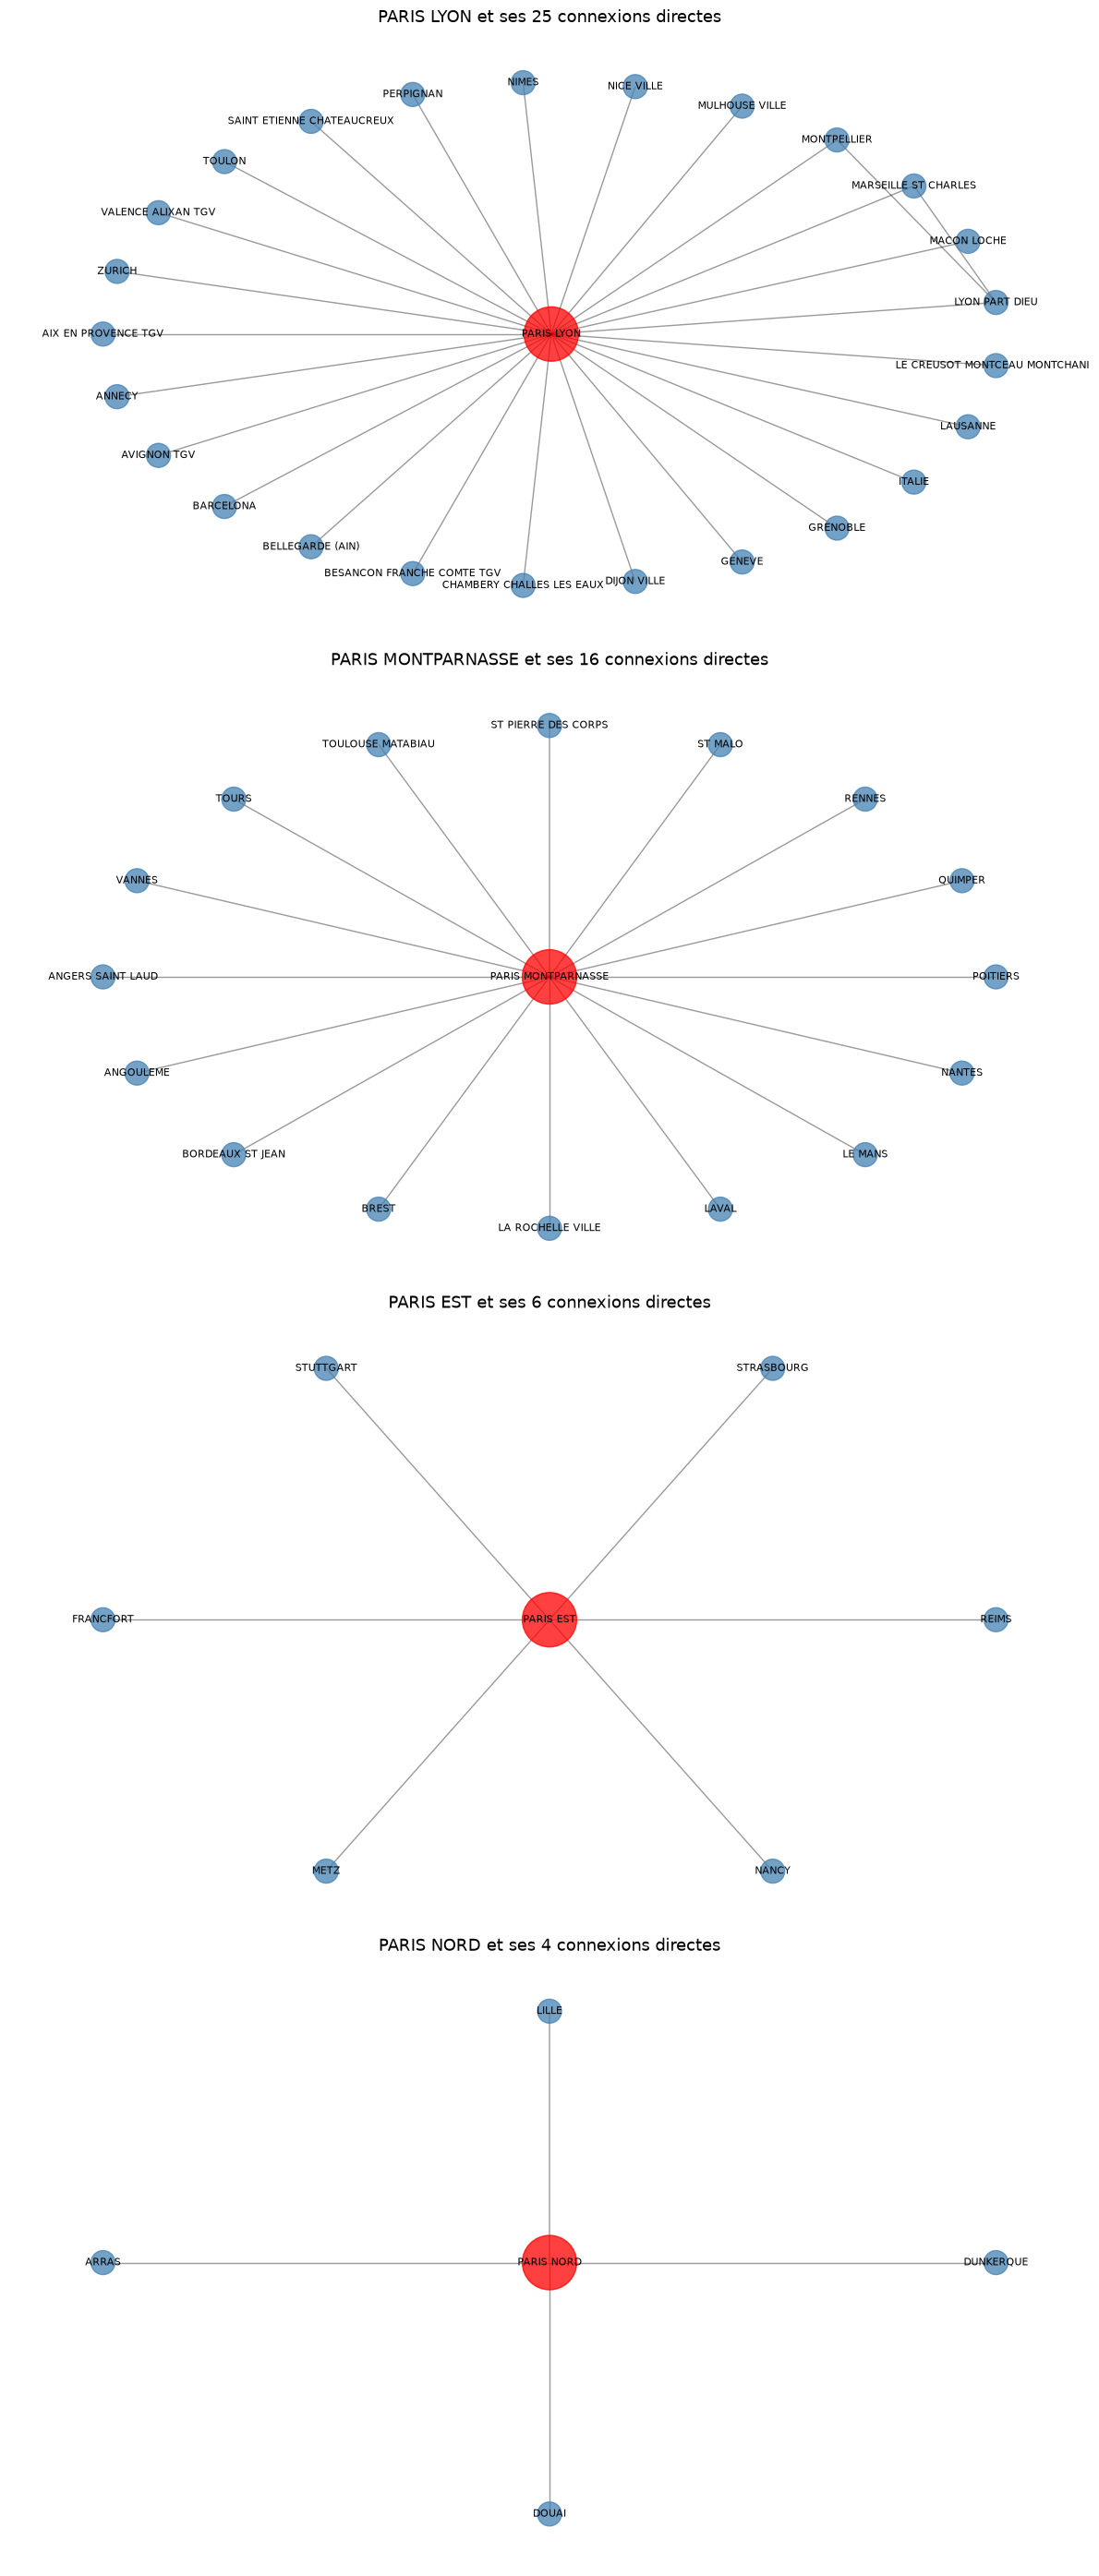

In [27]:

# On représente séparément les connexions directes des principales gares parisiennes
gares_paris = ["PARIS LYON", "PARIS MONTPARNASSE", "PARIS EST", "PARIS NORD"]

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(12, 28))

for ax, gare in zip(axes, gares_paris):
    # On récupère les gares directement connectées à chaque gare parisienne
    voisins = list(G.neighbors(gare))
    sous_graphe = G.subgraph([gare] + voisins)

    # On place la gare parisienne au centre et les autres autour
    pos = nx.shell_layout(sous_graphe, [[gare], voisins])

    # On distingue la gare parisienne par une taille plus grande et une couleur rouge
    tailles = [1800 if noeud == gare else 350 for noeud in sous_graphe.nodes()]
    couleurs = ["red" if noeud == gare else "steelblue" for noeud in sous_graphe.nodes()]

    # On affiche les gares, leurs connexions et leurs noms
    nx.draw_networkx_edges(sous_graphe, pos, alpha=0.4, ax=ax)
    nx.draw_networkx_nodes(sous_graphe, pos, node_size=tailles,
                           node_color=couleurs, alpha=0.75, ax=ax)
    nx.draw_networkx_labels(sous_graphe, pos, font_size=8, ax=ax)

    ax.set_title(f"{gare} et ses {len(voisins)} connexions directes",
                 fontsize=13)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [28]:

# On calcule le taux de retard des liaisons liées à chaque gare
taux_par_gare = {}

for gare in G.nodes():
    lignes = data_propre[
        (data_propre["gare_depart"] == gare) | (data_propre["gare_arrivee"] == gare)
    ]
    taux_par_gare[gare] = taux(lignes)

taux_par_gare = pd.Series(taux_par_gare, name="taux_moyen")

# On regroupe le degré, la centralité et le taux de retard de chaque gare
tableau_gares = pd.DataFrame({
    "degre": degres,
    "centralite": centralite,
    "taux_moyen": taux_par_gare
}).round(3)

# On affiche les 10 gares les plus centrales avec leurs taux de retard
print("Top 10 des gares les plus centrales et leur taux de retard :")
tableau_gares.sort_values("centralite", ascending=False).head(10)


Top 10 des gares les plus centrales et leur taux de retard :


,degre,centralite,taux_moyen
PARIS LYON,25,0.620,11.839
LYON PART DIEU,6,0.499,12.757
PARIS MONTPARNASSE,16,0.489,8.658
RENNES,3,0.449,8.394
NANTES,3,0.219,9.566
STRASBOURG,2,0.189,10.047
PARIS EST,6,0.166,9.830
LILLE,3,0.131,11.974
MARSEILLE ST CHARLES,6,0.115,14.982
PARIS NORD,4,0.102,6.659


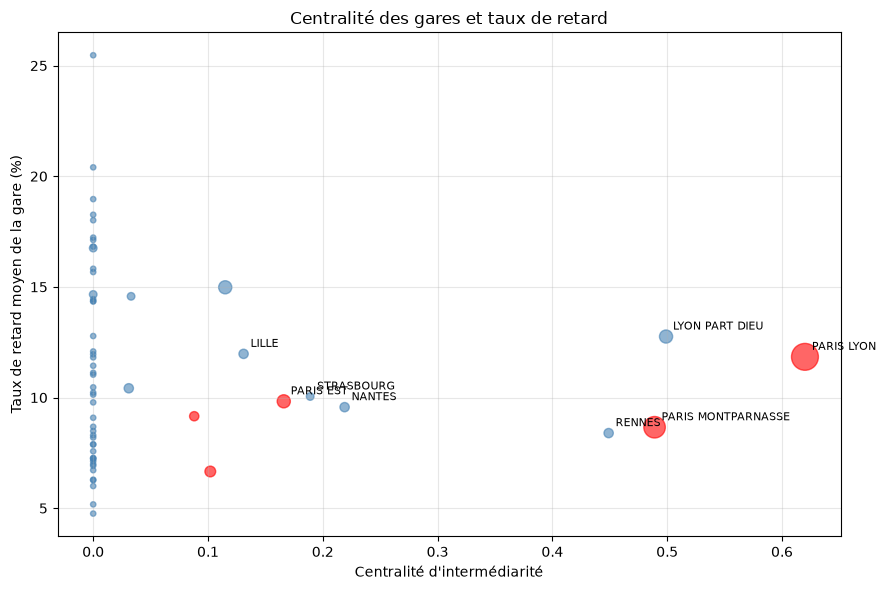


Corrélation de Spearman centralité vs taux : 0.003
p-value : 0.9807


In [29]:

from scipy.stats import spearmanr

# On regarde la relation entre la centralité des gares et leur taux de retard
fig, ax = plt.subplots(figsize=(9, 6))

# On met les gares de Paris en rouge et les autres en bleu
couleurs_gares = ["red" if "PARIS" in g else "steelblue" for g in tableau_gares.index]

# On affiche chaque gare avec une taille qui dépend de son nombre de connexions
ax.scatter(tableau_gares["centralite"], tableau_gares["taux_moyen"],
           s=tableau_gares["degre"] * 15, c=couleurs_gares, alpha=0.6)

# On affiche les noms des 8 gares les plus centrales
top_8 = tableau_gares.sort_values("centralite", ascending=False).head(8)
for gare, ligne in top_8.iterrows():
    ax.annotate(gare, (ligne["centralite"], ligne["taux_moyen"]),
                fontsize=8, xytext=(5, 5), textcoords="offset points")

# On ajoute les titres et la grille
ax.set_xlabel("Centralité d'intermédiarité")
ax.set_ylabel("Taux de retard moyen de la gare (%)")
ax.set_title("Centralité des gares et taux de retard")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# On calcule la corrélation de Spearman entre la centralité et le taux de retard
rho, pval = spearmanr(tableau_gares["centralite"], tableau_gares["taux_moyen"])

print(f"\nCorrélation de Spearman centralité vs taux : {rho:.3f}")
print(f"p-value : {pval:.4f}")


Ce qu'on retient de la section 6

Nous avons représenté le réseau TGV sous forme de graphe avec 59 gares et 65 connexions. Sa densité est faible (environ 4%), ce qui montre que les gares ne sont pas toutes directement reliées entre elles.

Les gares parisiennes dominent le classement par connectivité et par centralité. Paris Lyon arrive en tête avec 25 liaisons directes, suivie de Paris Montparnasse avec 16. Lyon Part Dieu se place en deuxième position par centralité d'intermédiarité, ce qui en fait un hub secondaire majeur du réseau, probablement parce qu'elle sert de relais pour les liaisons transversales.

La corrélation de Spearman entre la centralité d'une gare et le taux de retard moyen des liaisons qui la touchent est proche de zéro (0,003, p-value de 0,98). Autrement dit, être une gare centrale dans le réseau ne prédit pas les retards. Ce résultat suggère que la position d'une gare dans la structure explicite du réseau n'est pas, à elle seule, un bon indicateur de régularité.

Ce résultat ne veut pas dire que la structure ne compte pas. La section 5 avait déjà montré qu'au niveau des liaisons, le type (radiale, transversale, international) pèse fort sur les retards. L'effet se joue probablement au niveau des liaisons et pas des gares qui en concentrent plusieurs types.

Dans la prochaine section, on va chercher à regrouper les liaisons selon leurs caractéristiques statistiques pour voir si un réseau "caché" se dessine, différent de la carte géographique classique.